# A Primer on UQ in Machine Learning and Finance - Uncertainty quantification in option pricing
### From Black–Scholes to the uncertain volatility model

**Goal.** Imagine that a client asks us to price an option strategy today. We know the stock price and the terms of the contract, but we do not know exactly how volatile the market will be over the next six months. How much can this uncertainty affect the price? How can we account for it when selling or buying the strategy?

By the end of this exercise, you will be able to interpret an option payoff, price a bull call spread using Black–Scholes, propagate uncertainty about volatility into a range of prices, and understand why allowing volatility to change over time leads to a wider range.

*Source:* Avellaneda, M., Levy, A. & Parás, A. (1995). [Pricing and hedging derivative securities in markets with uncertain volatilities](https://doi.org/10.1080/13504869500000005), *Applied Mathematical Finance*, 2(2), 73–88.

In [1]:
# Run once

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Same visual language as the other UPC Quant workshops.
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.18,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "figure.dpi": 110})
RED = "#B01C2E"
BLUE = "#27658A"
GREY = "#675E61"

## 1. Our financial problem: pricing a bull call spread

A **European call option** gives its buyer the right, but not the obligation, to buy a stock at a fixed strike price $K$ on a future date $T$. If the stock price at maturity is $S_T$, the call pays

$$C_T=(S_T-K)^+=\max(S_T-K,0).$$

The buyer pays a premium today in exchange for this future payoff. A **bull call spread** combines two European calls with the same maturity:

- Buy a call with the lower strike $K_1=90$.
- Sell a call with the higher strike $K_2=100$.

The short call helps finance the long call, at the cost of capping the upside. This strategy expresses a moderately bullish view of the stock. Its payoff is

$$g(S_T)=(S_T-K_1)^+-(S_T-K_2)^+.$$

If $S_T\leq90$, the payoff is zero; if $90<S_T<100$, it increases with the stock price; if $S_T\geq100$, it is capped at 10. This is the payoff, **not the profit**: the initial premium has not yet been deducted.

We use the parameters of the numerical example in the paper (Figures 1 and 3), with an initial spot of 95 as in the last row of Table 1. All prices are per unit of the underlying; volatilities and the risk-free rate are annualised.

In [2]:
# Contract and market parameters
S0 = 95.0         # stock price TODAY (spot)
K_buy = 90.0      # strike of the long call
K_sell = 100.0    # strike of the short call
T = 0.5           # years to maturity (6 months)
r = 0.05          # continuously compounded risk-free rate, no dividends

sigma_bs = 0.25   # reference Black-Scholes volatility
sigma_min = 0.10  # lower bound for future volatility
sigma_max = 0.40  # upper bound for future volatility

### 1.1. The payoff function

In Python, `np.maximum` implements the positive part $(\cdot)^+$. The function below works for a single stock price or an entire array of prices. First evaluate three possible outcomes, then draw the complete payoff curve.

In [3]:
def spread_payoff(S_final):
    return np.maximum(S_final - K_buy, 0) - np.maximum(S_final - K_sell, 0)

for S_final in [85, 95, 105]:
    print(f"Stock finishes at {S_final}: payoff = {spread_payoff(S_final):.0f}")

Stock finishes at 85: payoff = 0
Stock finishes at 95: payoff = 5
Stock finishes at 105: payoff = 10


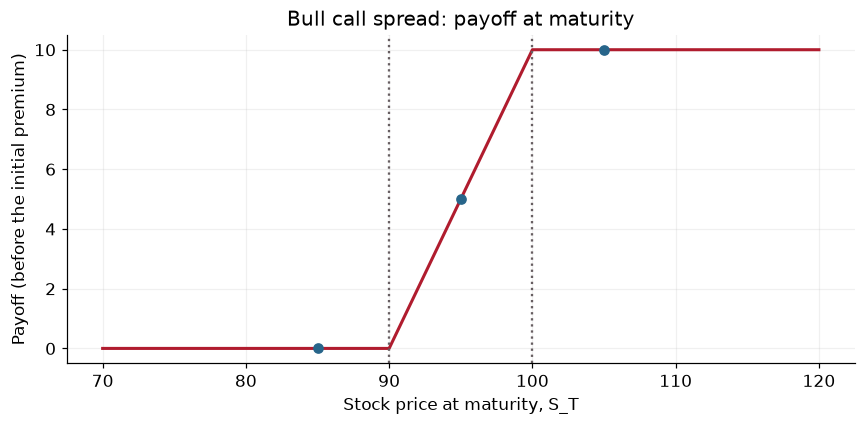

In [4]:
S_final = np.linspace(70, 120, 501)

plt.figure(figsize=(8, 4))
plt.plot(S_final, spread_payoff(S_final), color=RED, lw=2)
plt.scatter([85, 95, 105], spread_payoff(np.array([85, 95, 105])),
            color=BLUE, zorder=3)
plt.axvline(K_buy, ls=":", c=GREY)
plt.axvline(K_sell, ls=":", c=GREY)
plt.title("Bull call spread: payoff at maturity")
plt.xlabel("Stock price at maturity, S_T")
plt.ylabel("Payoff (before the initial premium)")
plt.tight_layout()
plt.show()

The shape of this curve will matter later. At the lower strike the slope increases, while at the upper strike it decreases. The portfolio therefore has both convex and concave regions, unlike a single call. Changes in volatility can affect these regions differently.

## 2. Black–Scholes: pricing with a known volatility

A payoff tells us what we receive at maturity. It does not tell us what the contract is worth today, because we do not know the future stock price.

The Black–Scholes model assumes a constant volatility $\sigma$ (a measure of the size of stock-return fluctuations) and a constant interest rate $r$. Under the model's risk-neutral pricing dynamics, the stock price satisfies

$$dS_t=rS_t\,dt+\sigma S_t\,dW_t,$$

where $W_t$ is Brownian motion. The expected discounted payoff gives the price:

$$V_{\mathrm{BS}}(S_0;\sigma)=e^{-rT}\mathbb E^{\mathbb Q_\sigma}[g(S_T)].$$

Here $\mathbb Q_\sigma$ is a pricing measure, not a prediction of real-world stock returns. Intuitively, the expectation averages over possible future stock prices, and discounting converts future cash flows into today's money.

For a European call with no dividends, Black–Scholes gives

$$C_{\mathrm{BS}}(S,K,\sigma,\tau)=S\Phi(d_1)-Ke^{-r\tau}\Phi(d_2),$$

$$d_1=\frac{\log(S/K)+(r+\sigma^2/2)\tau}{\sigma\sqrt{\tau}},
\qquad d_2=d_1-\sigma\sqrt{\tau},$$

where $\Phi$ is the standard normal cumulative distribution function and $\tau$ is time to maturity.

The spread is worth the difference between the two calls:

$$V_{\mathrm{BS}}(S;\sigma)=C_{\mathrm{BS}}(S,K_1,\sigma,T)-C_{\mathrm{BS}}(S,K_2,\sigma,T).$$

### 2.1. The pricing functions

`norm.cdf` computes $\Phi$. The first function prices a single call and the second combines both calls using the **same** volatility. We will reuse these functions throughout the notebook.

In [5]:
def call_bs(S, K, sigma, tau=T):
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * tau) / (sigma * np.sqrt(tau))
    d2 = d1 - sigma * np.sqrt(tau)
    return S * norm.cdf(d1) - K * np.exp(-r * tau) * norm.cdf(d2)

def spread_bs(S, sigma):
    return call_bs(S, K_buy, sigma) - call_bs(S, K_sell, sigma)

### 2.2. Let's price the strategy

Suppose we initially use a volatility of 25%. Calculate the premium of each call and the price of the spread. Compare that price with its payoff at maturity. For the profit example, we account for the time value of the premium by carrying it forward at rate $r$.

In [6]:
price_today = spread_bs(S0, sigma_bs)

print(f"Call 90 today:  {call_bs(S0, K_buy, sigma_bs):.2f}")
print(f"Call 100 today: {call_bs(S0, K_sell, sigma_bs):.2f}")
print(f"Spread today (spot={S0:.0f}, {T*12:.0f} months left): {price_today:.2f}")
print(f"Payoff if the stock finishes at {S0:.0f}: {spread_payoff(S0):.2f}")
print(f"Payoff if the stock finishes at 100: {spread_payoff(100):.2f}")
print(f"Profit at maturity if stock finishes at 105: "
      f"{spread_payoff(105) - price_today * np.exp(r*T):.2f}")

Call 90 today:  10.68
Call 100 today: 5.59
Spread today (spot=95, 6 months left): 5.09
Payoff if the stock finishes at 95: 5.00
Payoff if the stock finishes at 100: 10.00
Profit at maturity if stock finishes at 105: 4.78


We have obtained a single price, conditional on the assumption $\sigma=25\%$. However, the market may turn out to be calmer or more volatile. Even if the current implied volatility is 25%, there is no guarantee that future volatility will remain at that level.

## 3. What if volatility is uncertain?

This is the problem addressed by Avellaneda, Levy & Parás (1995). Rather than specify one exact volatility or a complete stochastic volatility model, they assume that future volatility stays within a prescribed band,

$$\sigma_{\min}\leq\sigma_t\leq\sigma_{\max}.$$

We use $[10\%,40\%]$. In practice, such bounds could be informed by historical volatility, implied volatility or stress scenarios. We treat the bounds as inputs, not estimates obtained from data.

There are two different interpretations of this assumption. Understanding the distinction between them is the main purpose of this exercise.

### 3.1. Unknown but constant volatility

First suppose that $\sigma$ is unknown but remains constant throughout the contract's lifetime. We can evaluate Black–Scholes for many values in the admissible range and compute

$$\underline V_{\mathrm{const}}(S)=\min_{\sigma\in[\sigma_{\min},\sigma_{\max}]}
V_{\mathrm{BS}}(S;\sigma),$$

$$\overline V_{\mathrm{const}}(S)=\max_{\sigma\in[\sigma_{\min},\sigma_{\max}]}
V_{\mathrm{BS}}(S;\sigma).$$

This is a simple example of **uncertainty propagation**: we propagate uncertainty in the input $\sigma$ through a pricing function and obtain a range of possible prices.

The code evaluates 61 equally spaced volatilities for each current stock price. Each row of `prices` contains the entire spread price curve for one volatility; the minimum and maximum across rows give approximate envelopes. We sweep the entire range because the extreme price of a spread need not occur at an extreme volatility.

In [7]:
S_today = np.linspace(60, 130, 281)
sigmas = np.linspace(sigma_min, sigma_max, 61)

# Each row prices the WHOLE spread with a different constant sigma.
prices = np.array([spread_bs(S_today, s) for s in sigmas])
bs_min = prices.min(axis=0)
bs_max = prices.max(axis=0)

for S in [85, 90, 95, 105]:
    i = np.argmin(abs(S_today - S))
    print(f"Spot={S}: {bs_min[i]:.2f} (sigma={sigmas[prices[:, i].argmin()]:.0%})"
          f" – {bs_max[i]:.2f} (sigma={sigmas[prices[:, i].argmax()]:.0%})")

Spot=85: 1.23 (sigma=10%) – 3.21 (sigma=40%)
Spot=90: 3.35 (sigma=10%) – 3.96 (sigma=34%)
Spot=95: 4.68 (sigma=40%) – 6.01 (sigma=10%)
Spot=105: 6.03 (sigma=40%) – 9.22 (sigma=10%)


Notice that at a spot of 85 the largest price occurs at high volatility, whereas at a spot of 105 the largest price occurs at low volatility. At a spot of 90, the grid maximum occurs at an intermediate volatility. This reflects the two opposing option positions.

### 3.2. Volatility that can change during the contract

Now imagine that future volatility can change with time and with the stock price, as long as it stays between 10% and 40%. A single constant value is no longer enough to describe all admissible scenarios.

Let $\mathcal Q$ be the family of risk-neutral pricing measures generated by the allowed volatility processes. The robust lower and upper prices are

$$V^-(S_0)=\inf_{\mathbb Q\in\mathcal Q}
\mathbb E^{\mathbb Q}[e^{-rT}g(S_T)],$$

$$V^+(S_0)=\sup_{\mathbb Q\in\mathcal Q}
\mathbb E^{\mathbb Q}[e^{-rT}g(S_T)].$$

These are lower and upper expectations over a family of models. There is no need to put a probability distribution on volatility scenarios. Because the constant-volatility models are a subset of the variable-volatility models, the robust range must be at least as wide as the constant-volatility range (in the exact model).

#### The Black–Scholes–Barenblatt equation (optional mathematical detail)

The paper characterises these prices with a nonlinear PDE. Writing $V=V(t,S)$ with $V(T,S)=g(S)$, the upper-bound equation is

$$\partial_t V+rS\partial_S V-rV+
\max_{\sigma\in[\sigma_{\min},\sigma_{\max}]}
\left\{\tfrac12\sigma^2 S^2\partial_{SS}V\right\}=0.$$

For the lower bound replace the maximum by a minimum. The quantity $\Gamma=\partial_{SS}V$ is called *gamma* in options pricing: it measures local curvature of the price. For the upper price, high volatility is selected where $\Gamma>0$ and low volatility where $\Gamma<0$; the lower price reverses the choice. When $\Gamma=0$, both choices are equivalent in the PDE.

You do not need to solve this equation by hand. We will approximate it using backward induction on a tree, which is much easier to visualise.

### 3.3. A trinomial tree: how the algorithm works

Divide the remaining time into $N$ short steps, $\Delta t=T/N$. At each step the log-price $x=\log S$ can move up by $\Delta x$, stay unchanged, or move down by $\Delta x$.

```
                  x + Δx     (up)
                ↗
     x ────────── x          (middle)
                ↘
                  x - Δx     (down)
```

The three transition probabilities approximate the mean and variance of a small risk-neutral log-price increment,

$$\mu=r-\tfrac12\sigma^2,\qquad
\mathbb E[\Delta x_{\mathrm{random}}]\approx\mu\Delta t,\qquad
\operatorname{Var}(\Delta x_{\mathrm{random}})\approx\sigma^2\Delta t.$$

Specifically, with the fixed spatial step $\Delta x=\sigma_{\max}\sqrt{\Delta t}$, we use

$$p_u=\frac{\sigma^2\Delta t}{2(\Delta x)^2}+
\frac{\mu\Delta t}{2\Delta x},\qquad
p_d=\frac{\sigma^2\Delta t}{2(\Delta x)^2}-
\frac{\mu\Delta t}{2\Delta x},\qquad p_m=1-p_u-p_d.$$

If the three future values are $V_u,V_m,V_d$, the approximate continuation price is

$$Q_\sigma=e^{-r\Delta t}(p_u V_u+p_m V_m+p_d V_d).$$

Start from the payoff at maturity and work backwards. At each node, evaluate the continuation price with $\sigma_{\min}$ and $\sigma_{\max}$. Keep the larger price for the upper bound or the smaller price for the lower bound. Repeat until today. The choice can change at every node, rather than being fixed for the whole contract.

The two functions below implement precisely these steps. NumPy's array slicing lets us process all stock-price nodes simultaneously. This is a teaching implementation of a log-price trinomial approximation, not the paper's full hedging algorithm.

In [8]:
def continuation(V, sigma, dt, dx):
    # Discounted average over the up, middle and down successor nodes.
    mu = r - 0.5 * sigma**2
    p_up = 0.5 * sigma**2 * dt / dx**2 + 0.5 * mu * dt / dx
    p_dn = 0.5 * sigma**2 * dt / dx**2 - 0.5 * mu * dt / dx
    return np.exp(-r * dt) * (p_up * V[2:] +
                             (1 - p_up - p_dn) * V[1:-1] + p_dn * V[:-2])

def bsb_bound(bound, n_steps=400, low=sigma_min, high=sigma_max):
    dt = T / n_steps
    dx = high * np.sqrt(dt)                  # log-price grid spacing
    extra = int(np.ceil(0.5 / dx))           # cover current spots away from S0
    j = np.arange(-(n_steps + extra), n_steps + extra + 1)
    S = S0 * np.exp(j * dx)                  # terminal stock-price grid
    V = spread_payoff(S)
    choose = np.maximum if bound == "upper" else np.minimum
    for _ in range(n_steps):
        # At each node, choose the more extreme continuation.
        V = choose(continuation(V, low, dt, dx), continuation(V, high, dt, dx))
        S = S[1:-1]                          # one fewer node at each end
    return S, V                              # current stock prices and bounds

### 3.4. Compute the robust prices

The tree approximates the continuous-time model, so the number of time steps affects numerical accuracy. We first use 400 steps, then check whether the estimates stabilise as we refine the tree. (The displayed prices are estimates, not exact arbitrage bounds of a finite-step market.)

In [9]:
S_tree, bsb_lower = bsb_bound("lower")
_, bsb_upper = bsb_bound("upper")
print(f"BSB at spot={S0:.0f}: {np.interp(S0, S_tree, bsb_lower):.2f}"
      f" – {np.interp(S0, S_tree, bsb_upper):.2f}")

for n in [100, 400, 1600]:
    Sa, lower_n = bsb_bound("lower", n)
    _, upper_n = bsb_bound("upper", n)
    print(f"N={n:4d}: {np.interp(S0, Sa, lower_n):.3f}"
          f" – {np.interp(S0, Sa, upper_n):.3f}")

BSB at spot=95: 2.83 – 7.43
N= 100: 2.794 – 7.415
N= 400: 2.830 – 7.431
N=1600: 2.836 – 7.442


## 4. Compare the methods: uncertainty changes the price

We now reproduce the idea of Figure 3 of Avellaneda et al. (1995), adding our 25% Black–Scholes reference curve. The graph compares three assumptions:

| Method | Assumption | Output |
|---|---|---|
| Black–Scholes, 25% | Known constant volatility | Single price |
| Black–Scholes envelope | Unknown constant volatility between 10% and 40% | Price range |
| Black–Scholes–Barenblatt (BSB) | Volatility may vary within the band | Robust price range |

The horizontal axis is the **stock price today**, not the terminal stock price in Section 1. Each curve answers the question: what would the same spread be worth now if the current stock price were different?

The plotting function uses precomputed price curves. We will reuse it to investigate different current spot prices without changing the contract.

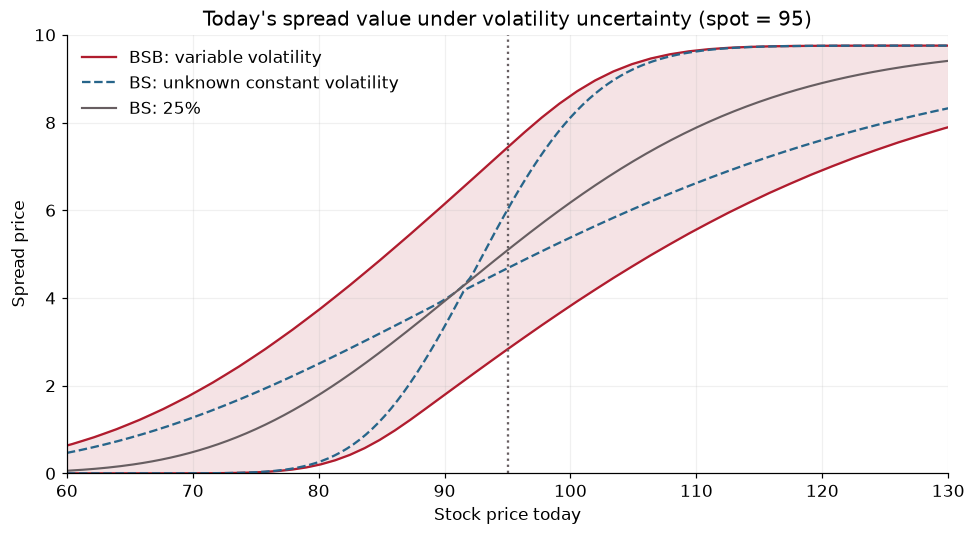

BS 25%:              5.09
BS constant range:   4.68 – 6.01
BSB variable range:  2.83 – 7.43


In [10]:
def plot_prices(S, tree=S_tree, lower=bsb_lower, upper=bsb_upper,
                const_lower=bs_min, const_upper=bs_max):
    plt.figure(figsize=(9, 5))
    plt.fill_between(tree, lower, upper, color=RED, alpha=0.12)
    plt.plot(tree, upper, c=RED, label="BSB: variable volatility")
    plt.plot(tree, lower, c=RED)
    plt.plot(S_today, const_upper, "--", c=BLUE, label="BS: unknown constant volatility")
    plt.plot(S_today, const_lower, "--", c=BLUE)
    plt.plot(S_today, spread_bs(S_today, sigma_bs), c=GREY, lw=1.4, label="BS: 25%")
    plt.axvline(S, ls=":", c=GREY)
    plt.xlim(60, 130)
    plt.ylim(0, 10)
    plt.title(f"Today's spread value under volatility uncertainty (spot = {S:.0f})")
    plt.xlabel("Stock price today")
    plt.ylabel("Spread price")
    plt.legend(frameon=False, loc="upper left")
    plt.tight_layout()
    plt.show()

    print(f"BS 25%:              {spread_bs(S, sigma_bs):.2f}")
    print(f"BS constant range:   {np.interp(S, S_today, const_lower):.2f}"
          f" – {np.interp(S, S_today, const_upper):.2f}")
    print(f"BSB variable range:  {np.interp(S, tree, lower):.2f}"
          f" – {np.interp(S, tree, upper):.2f}")

plot_prices(S0)

### 4.1. How should we read the graph?

At a spot of 95, the 25% Black–Scholes price is about 5.09. The constant-volatility envelope is about [4.68, 6.01], whereas the BSB range is about [2.83, 7.43] with 400 steps. For comparison, Table 1 of the original paper reports a mid-volatility value of 5.09 and BSB bounds of [2.83, 7.44]. Figure 3 compares the constant and variable volatility envelopes. Small differences reflect numerical discretisation.

**Why do the constant-volatility envelopes change shape?** At low spot prices, greater volatility can help the spread reach its profitable region. At high spot prices, less volatility can help preserve its near-maximum payoff. The curves for individual constant volatilities can cross, but their upper and lower envelopes cannot cross; which volatility attains the envelope can change across spots.

**Why is one curve much steeper?** Low volatility implies relatively little diffusion, so the price transitions more sharply between its low and high values; higher volatility smooths that transition. The terminal payoff itself is continuous and piecewise linear.

**Why is the red band wider?** The BSB procedure allows a different volatility scenario at each node, including changes in volatility as the stock price evolves. It therefore considers more possibilities than using a single constant volatility.

This interval is **not a 90% or 95% prediction interval**. It is a range of model-consistent present values, conditional on the assumed volatility band, the market assumptions and the numerical approximation. It does not assign probabilities to prices within the range.

In [11]:
# Numerical check: the constant-volatility band should lie inside the BSB band.
lower_on_grid = np.interp(S_today, S_tree, bsb_lower)
upper_on_grid = np.interp(S_today, S_tree, bsb_upper)
inside = np.all(bs_min >= lower_on_grid - 1e-2) and np.all(bs_max <= upper_on_grid + 1e-2)
print("Constant-volatility band inside BSB (within numerical tolerance)?", inside)

Constant-volatility band inside BSB (within numerical tolerance)? True


## 5. Try it yourself

**A. Change the current spot.** What happens if the stock is trading at 85 rather than 95? What happens if it is trading at 105? Which range is wider? Try to explain the results using the shape of the original payoff.

A higher current spot generally puts the spread closer to its maximum terminal payoff, but the future stock price is still uncertain.

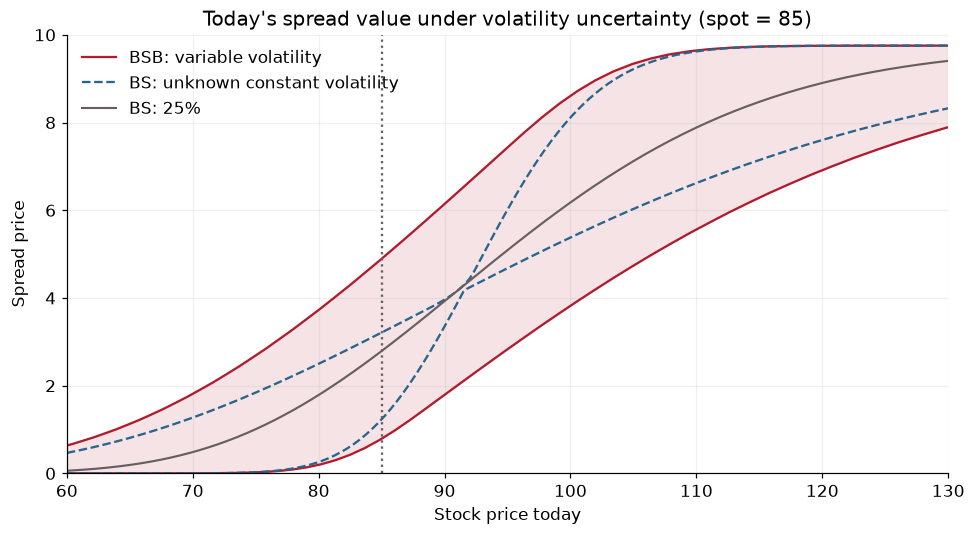

BS 25%:              2.79
BS constant range:   1.23 – 3.21
BSB variable range:  0.79 – 4.89


In [12]:
plot_prices(85)

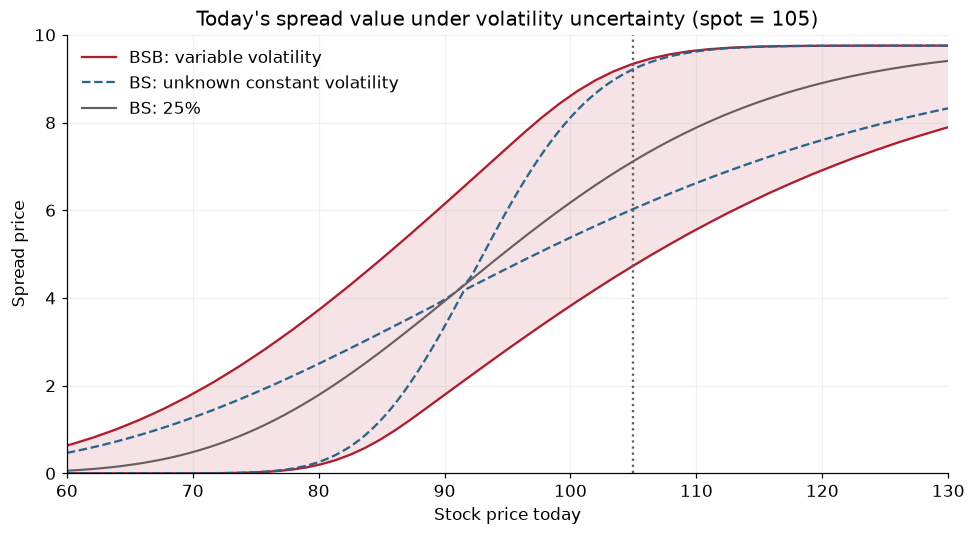

BS 25%:              7.12
BS constant range:   6.03 – 9.22
BSB variable range:  4.74 – 9.34


In [13]:
plot_prices(105)

**B. Remove volatility uncertainty.** Set both bounds to 25%. What should happen to the two price ranges?

When there is only one admissible volatility, both robust prices should coincide with the Black–Scholes price in the continuous-time limit. The numerical tree may still have a small approximation error. The following cell performs this experiment without overwriting the original volatility band.

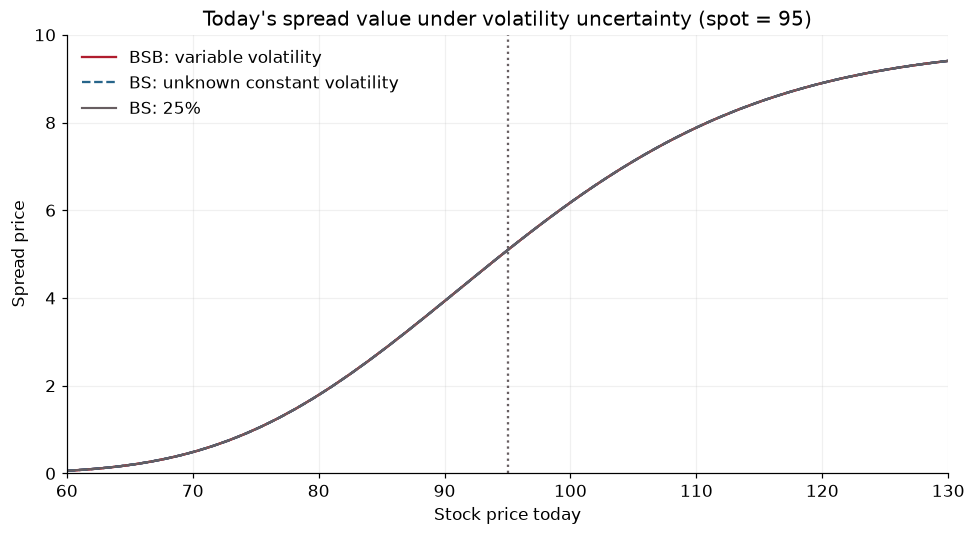

BS 25%:              5.09
BS constant range:   5.09 – 5.09
BSB variable range:  5.09 – 5.09
Maximum difference between tree and BS on today's grid: 0.0019


In [14]:
fixed_sigma = 0.25
constant_price = spread_bs(S_today, fixed_sigma)
S_fixed, fixed_lower = bsb_bound("lower", low=fixed_sigma, high=fixed_sigma)
_, fixed_upper = bsb_bound("upper", low=fixed_sigma, high=fixed_sigma)

plot_prices(S0, S_fixed, fixed_lower, fixed_upper, constant_price, constant_price)
print(f"Maximum difference between tree and BS on today's grid: "
      f"{np.max(abs(fixed_upper - spread_bs(S_fixed, fixed_sigma))):.4f}")

## 6. What can we do with this information?

**Robust pricing and hedging.** Suppose a client wants to buy this spread at a spot of 95. The standard model prices it at about 5.09. If the seller wants to protect against all admissible volatility paths using the underlying stock and cash, the BSB upper price of approximately 7.43 is an estimate of the initial capital needed for a superhedge in the model's idealised continuous-time market. The difference of about 2.34 is an illustration of the additional capital implied by that robustness requirement. Actual hedging costs depend on transaction costs, discrete rebalancing and whether the assumed volatility bounds hold.

**Portfolio risk.** A desk holding both long and short options should assess the volatility exposure of the whole portfolio. For a single call, the price is increasing in volatility. For a spread, the exposures can partially offset. Choosing separate worst-case volatilities for each option can therefore be unnecessarily conservative. Pricing the combined payoff under common admissible scenarios is one of the central ideas of the paper.

### Takeaways

- Black–Scholes gives a price conditional on a volatility model.
- A sensitivity analysis with constant volatility propagates input uncertainty into a range of prices.
- The uncertain volatility model allows volatility to change and captures additional model uncertainty through lower and upper prices.
- The bounds are only as credible as the assumptions defining the family of models. They are not statistical coverage guarantees.